# QueueLess — Computer Vision Module

Detects people, assigns them to checkout lanes, and produces the data the
waiting-time model needs: a per-second count log and a per-person wait log.

**Fixes applied over the previous version**
1. Lane membership uses the **foot point** (bottom-centre of the box), not the box centre.
2. Counts are **median-smoothed** over 1 second, so a single missed detection no longer flips the number.
3. ROIs are **normalised trapezoids** that follow the lane perspective and reach the bottom of the frame.
4. The model is **instantiated once**, so ByteTrack IDs stay continuous.
5. Track IDs are used to measure **per-person waiting time** (enter -> exit).
6. Everything is written to **CSV** for the prediction model.
7. A short **dwell filter** rejects people merely walking past a lane.

## 1. Setup

In [ ]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 9.4 MB/s eta 0:00:00


In [ ]:
import cv2
import numpy as np
import pandas as pd
from collections import deque, defaultdict
from ultralytics import YOLO
from IPython.display import display, Image as IPImage

# FIX 4: load the model exactly ONCE for the whole notebook.
# Re-creating it resets the tracker and restarts the IDs.
model = YOLO("yolo26n.pt")

print("Model loaded once. Tracker state will persist across frames.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded once. Tracker state will persist across frames.


## 2. Upload the CCTV clip

In [ ]:
from google.colab import files

uploaded = files.upload()
video_path = list(uploaded.keys())[0]

cap = cv2.VideoCapture(video_path)
FPS    = cap.get(cv2.CAP_PROP_FPS) or 24.0
WIDTH  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES= int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

print(f"{video_path}  |  {WIDTH}x{HEIGHT}  |  {FPS} fps  |  {NFRAMES} frames")

Saving Create_a_realistic_second_C.mp4 to Create_a_realistic_second_C.mp4
Create_a_realistic_second_C.mp4  |  1280x720  |  24.0 fps  |  240 frames


## 3. Configuration

ROIs are stored as **fractions of frame width/height**, so the same values work on any
camera resolution. Each lane is a trapezoid: narrow at the far end, wide at the near end,
following the perspective of the aisle. Run the preview cell below and adjust the numbers
until each box hugs one lane only.

In [ ]:
# FIX 3: normalised trapezoid ROIs, extended to the bottom edge of the frame.
QUEUE_ROIS_NORM = {
    "Q1": [(0.06, 0.35), (0.19, 0.35), (0.22, 1.00), (0.03, 1.00)],
    "Q2": [(0.34, 0.38), (0.47, 0.38), (0.52, 1.00), (0.29, 1.00)],
    "Q3": [(0.65, 0.30), (0.80, 0.30), (0.83, 1.00), (0.62, 1.00)],
}

LANE_NAMES  = list(QUEUE_ROIS_NORM.keys())
LANE_COLORS = {"Q1": (255, 0, 0), "Q2": (0, 165, 255), "Q3": (0, 200, 0)}

CONF            = 0.25   # single confidence threshold used everywhere
MIN_DWELL_SEC   = 1.5    # FIX 7: must stand in the lane this long to count as queuing
EXIT_GRACE_SEC  = 1.0    # tolerate this much occlusion before calling it an exit
SMOOTH_SEC      = 1.0    # FIX 2: median window for the displayed count
ALERT_THRESHOLD = 5      # people in one lane -> tell the manager to open a counter

def to_pixels(norm_pts, w, h):
    return (np.array(norm_pts, dtype=np.float32) * [w, h]).astype(np.int32)

QUEUE_ROIS = {name: to_pixels(pts, WIDTH, HEIGHT)
              for name, pts in QUEUE_ROIS_NORM.items()}

def assign_lane(foot_point):
    """Return the lane a floor position belongs to, or None."""
    for name, poly in QUEUE_ROIS.items():
        if cv2.pointPolygonTest(poly, foot_point, False) >= 0:
            return name
    return None

print("ROIs in pixels:")
for k, v in QUEUE_ROIS.items():
    print(" ", k, v.tolist())

ROIs in pixels:
  Q1 [[76, 251], [243, 251], [281, 720], [38, 720]]
  Q2 [[435, 273], [601, 273], [665, 720], [371, 720]]
  Q3 [[831, 216], [1024, 216], [1062, 720], [793, 720]]


### Preview the ROIs before running the full video

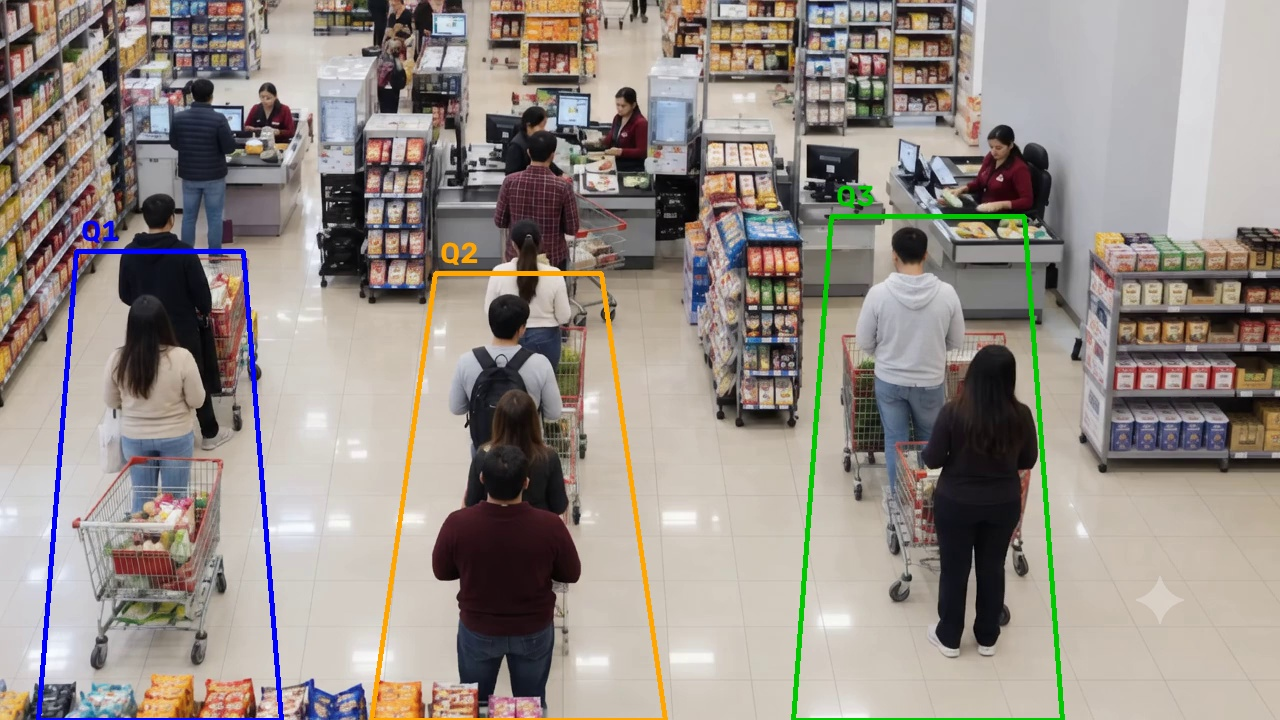

In [ ]:
cap = cv2.VideoCapture(video_path)
ok, frame = cap.read()
cap.release()

preview = frame.copy()
for name, poly in QUEUE_ROIS.items():
    cv2.polylines(preview, [poly], True, LANE_COLORS[name], 3)
    lx, ly = int(poly[0][0]) + 5, int(poly[0][1]) - 10
    cv2.putText(preview, name, (lx, ly),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, LANE_COLORS[name], 3)

_, buf = cv2.imencode(".jpg", preview)
display(IPImage(data=buf.tobytes()))

## 4. Main pass

One loop over the video that does everything: track, assign, smooth, log, annotate.

The **foot point** is the key change. The centre of a person's bounding box sits at
chest height, which in an angled view floats over the neighbouring lane. The bottom-centre
of the box is where the person's feet meet the floor, which is where they actually are.

In [ ]:
out_raw = "queueless_annotated_raw.mp4"
writer = cv2.VideoWriter(out_raw, cv2.VideoWriter_fourcc(*"mp4v"),
                         FPS, (WIDTH, HEIGHT))

min_dwell_f = int(MIN_DWELL_SEC * FPS)
grace_f     = int(EXIT_GRACE_SEC * FPS)
smooth_f    = max(1, int(SMOOTH_SEC * FPS))

history   = {n: deque(maxlen=smooth_f) for n in LANE_NAMES}  # for median smoothing
first_seen = {}   # (track_id, lane) -> frame index of first appearance
last_seen  = {}   # (track_id, lane) -> frame index of most recent appearance
waits      = []   # completed per-person waiting times
count_log  = []   # per-frame counts

cap = cv2.VideoCapture(video_path)
idx = 0

while cap.isOpened():
    ok, frame = cap.read()
    if not ok:
        break

    # persist=True keeps ByteTrack IDs stable because the model is never reloaded
    result = model.track(frame, persist=True, tracker="bytetrack.yaml",
                         classes=[0], conf=CONF, verbose=False)[0]

    raw = {n: 0 for n in LANE_NAMES}

    if result.boxes is not None and result.boxes.id is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        ids   = result.boxes.id.int().cpu().tolist()

        for box, tid in zip(boxes, ids):
            x1, y1, x2, y2 = map(int, box)

            # FIX 1: foot point instead of box centre
            fx, fy = int((x1 + x2) / 2), int(y2)
            lane = assign_lane((float(fx), float(fy)))

            if lane is None:
                continue

            key = (tid, lane)
            first_seen.setdefault(key, idx)
            last_seen[key] = idx

            # FIX 7: only count once the person has actually stopped here
            dwelled = idx - first_seen[key] >= min_dwell_f
            if dwelled:
                raw[lane] += 1

            col = LANE_COLORS[lane] if dwelled else (150, 150, 150)
            cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
            cv2.circle(frame, (fx, fy), 5, col, -1)
            cv2.putText(frame, f"ID{tid}", (x1, max(y1 - 6, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)

    # FIX 5: an ID that has been gone long enough has finished queuing
    for key, last in list(last_seen.items()):
        if idx - last > grace_f:
            dwell_frames = last - first_seen[key]
            if dwell_frames >= min_dwell_f:
                waits.append({"track_id": key[0], "lane": key[1],
                              "enter_sec": round(first_seen[key] / FPS, 2),
                              "exit_sec":  round(last / FPS, 2),
                              "wait_sec":  round(dwell_frames / FPS, 2)})
            del first_seen[key], last_seen[key]

    # FIX 2: publish the median over the last second, not the instantaneous count
    smooth = {}
    for n in LANE_NAMES:
        history[n].append(raw[n])
        smooth[n] = int(np.median(history[n]))

    row = {"frame": idx, "time_sec": round(idx / FPS, 2)}
    for n in LANE_NAMES:
        row[f"{n}_raw"] = raw[n]
        row[f"{n}_count"] = smooth[n]
    count_log.append(row)

    # overlay
    for n in LANE_NAMES:
        cv2.polylines(frame, [QUEUE_ROIS[n]], True, LANE_COLORS[n], 3)
    for i, n in enumerate(LANE_NAMES):
        cv2.putText(frame, f"{n}: {smooth[n]}", (20, 40 + i * 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, LANE_COLORS[n], 2)

    best = min(LANE_NAMES, key=lambda n: smooth[n])
    cv2.putText(frame, f"Shortest: {best}", (20, 40 + len(LANE_NAMES) * 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    if max(smooth.values()) >= ALERT_THRESHOLD:
        cv2.putText(frame, "ALERT: open another counter", (20, HEIGHT - 25),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)

    writer.write(frame)
    idx += 1

# flush anyone still in a lane when the clip ends
for key, last in last_seen.items():
    dwell_frames = last - first_seen[key]
    if dwell_frames >= min_dwell_f:
        waits.append({"track_id": key[0], "lane": key[1],
                      "enter_sec": round(first_seen[key] / FPS, 2),
                      "exit_sec":  round(last / FPS, 2),
                      "wait_sec":  round(dwell_frames / FPS, 2),
                      "censored":  True})

cap.release()
writer.release()
print(f"Processed {idx} frames.")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 317ms
Prepared 1 package in 53ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Processed 240 frames.


## 5. Outputs for the prediction model

Two CSVs. `queue_counts.csv` is the time series of how many people were in each lane.
`queue_waits.csv` is one row per person, with how long they stood there — these are the
**labels** your waiting-time model trains on. Rows marked `censored` were still queuing
when the clip ended, so their wait is a lower bound; drop them or handle them as censored
observations during training.

In [ ]:
counts_df = pd.DataFrame(count_log)
waits_df  = pd.DataFrame(waits)
if "censored" in waits_df.columns:
    waits_df["censored"] = waits_df["censored"].fillna(False)
else:
    waits_df["censored"] = False

counts_df.to_csv("queue_counts.csv", index=False)
waits_df.to_csv("queue_waits.csv", index=False)

print("queue_counts.csv", counts_df.shape)
display(counts_df.head())
print("queue_waits.csv", waits_df.shape)
display(waits_df.head(20))

queue_counts.csv (240, 8)


/tmp/ipykernel_4825/1033547692.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  waits_df["censored"] = waits_df["censored"].fillna(False)


,frame,time_sec,Q1_raw,Q1_count,Q2_raw,Q2_count,Q3_raw,Q3_count
0,0,0.00,0,0,0,0,0,0
1,1,0.04,0,0,0,0,0,0
2,2,0.08,0,0,0,0,0,0
3,3,0.12,0,0,0,0,0,0
4,4,0.17,0,0,0,0,0,0


queue_waits.csv (20, 6)


,track_id,lane,enter_sec,exit_sec,wait_sec,censored
0,3,Q1,0.00,2.58,2.58,False
1,27,Q3,0.92,2.71,1.79,False
2,13,Q2,0.00,2.79,2.79,False
3,11,Q2,0.00,2.88,2.88,False
4,14,Q2,0.00,3.33,3.33,False
5,12,Q2,0.00,3.88,3.88,False
6,9,Q3,0.00,4.42,4.42,False
7,34,Q2,3.25,5.62,2.38,False
8,1,Q2,0.00,9.96,9.96,True
9,2,Q3,0.00,9.96,9.96,True


### Stability check — the counts should now be flat when nobody joins or leaves

Q1: raw min/max = 0/3   smoothed min/max = 0/3   smoothed changes = 3
Q2: raw min/max = 0/7   smoothed min/max = 0/6   smoothed changes = 11
Q3: raw min/max = 0/4   smoothed min/max = 0/3   smoothed changes = 7


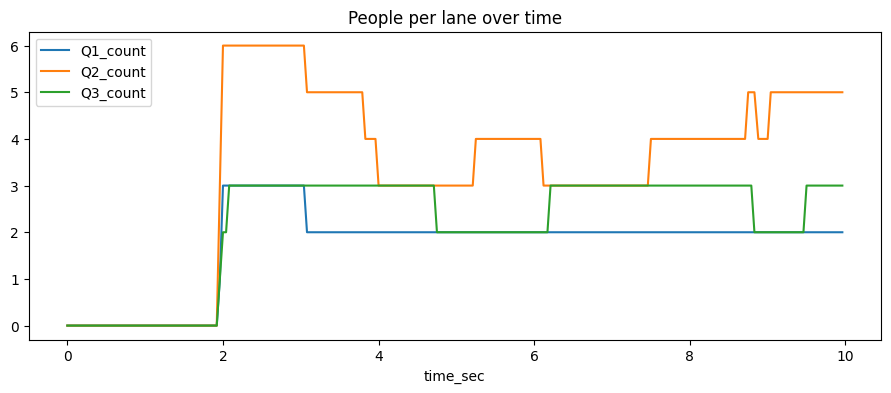

In [ ]:
for n in LANE_NAMES:
    raw_s, sm_s = counts_df[f"{n}_raw"], counts_df[f"{n}_count"]
    print(f"{n}: raw min/max = {raw_s.min()}/{raw_s.max()}   "
          f"smoothed min/max = {sm_s.min()}/{sm_s.max()}   "
          f"smoothed changes = {(sm_s.diff() != 0).sum() - 1}")

counts_df.plot(x="time_sec", y=[f"{n}_count" for n in LANE_NAMES],
               figsize=(11, 4), title="People per lane over time");

### Per-lane summary, recommendation and manager alert

In [ ]:
completed = waits_df[~waits_df["censored"]]

summary = []
for n in LANE_NAMES:
    lane_waits = completed[completed["lane"] == n]["wait_sec"]
    current = int(counts_df.iloc[-1][f"{n}_count"])
    # service time per person, falling back to a default until enough data exists
    per_person = lane_waits.mean() if len(lane_waits) >= 3 else 45.0
    summary.append({"lane": n,
                    "people_now": current,
                    "observed_waits": len(lane_waits),
                    "avg_wait_sec": round(lane_waits.mean(), 1) if len(lane_waits) else None,
                    "predicted_wait_sec": round(current * per_person, 1)})

summary_df = pd.DataFrame(summary)
display(summary_df)

best = summary_df.loc[summary_df["predicted_wait_sec"].idxmin()]
print(f"\nRecommend counter {best['lane']} "
      f"(~{best['predicted_wait_sec']:.0f} s wait, {best['people_now']} ahead)")

busiest = summary_df.loc[summary_df["people_now"].idxmax()]
if busiest["people_now"] >= ALERT_THRESHOLD:
    print(f"MANAGER ALERT: {busiest['lane']} has {busiest['people_now']} people — open another counter.")
else:
    print("No congestion alert.")

,lane,people_now,observed_waits,avg_wait_sec,predicted_wait_sec
0,Q1,2,1,2.6,90.0
1,Q2,5,5,3.1,15.3
2,Q3,3,2,3.1,135.0



Recommend counter Q2 (~15 s wait, 5 ahead)
MANAGER ALERT: Q2 has 5 people — open another counter.


## 6. Final video

Re-encoded to H.264 so it plays in a browser and in slides. `mp4v` often will not.

In [ ]:
out_final = "QUEUELESS_final_output.mp4"
!ffmpeg -y -loglevel error -i {out_raw} -c:v libx264 -pix_fmt yuv420p {out_final}
print("Written:", out_final)

Written: QUEUELESS_final_output.mp4


In [ ]:
from IPython.display import Video
Video(out_final, embed=True, width=900)

In [ ]:
from google.colab import files

files.download(out_final)
files.download("queue_counts.csv")
files.download("queue_waits.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Validation (do this before you write it up)

Nothing above proves the counts are right. Sample ~20 frames spread across the clip,
count the people in each lane by eye, put them in `truth`, and report the error.
A single MAE number is worth more in your report than any amount of annotated video.

In [ ]:
# frame index -> {lane: true number of people queuing}
truth = {
    0:   {"Q1": 2, "Q2": 3, "Q3": 2},
    # 30:  {"Q1": ?, "Q2": ?, "Q3": ?},
    # ... fill in ~20 sampled frames
}

if len(truth) >= 2:
    errs = []
    for f, t in truth.items():
        row = counts_df[counts_df["frame"] == f]
        if row.empty:
            continue
        for n in LANE_NAMES:
            errs.append(abs(int(row.iloc[0][f"{n}_count"]) - t[n]))
    print(f"MAE across {len(truth)} frames x {len(LANE_NAMES)} lanes: {np.mean(errs):.2f} people")
else:
    print("Fill in `truth` with more frames to compute MAE.")

Fill in `truth` with more frames to compute MAE.


### Known limitations to state in your report

- Tested on a short, static-camera clip with no queue turnover. Real CCTV brings
  occlusion, varying light and camera shake.
- Staff behind counters are detected as people; the ROIs exclude them geometrically,
  which will need re-tuning for any new camera.
- `predicted_wait_sec` above is a placeholder (people x average service time). Replacing
  it with a model trained on `queue_waits.csv` is the next stage of the project.